# COU 07506 Digital Signal Processing — Week 1, Lab 0
## Setting Up the DSP Laboratory: first signals

| Item | Value |
|---|---|
| Week / Lab | 1 — Lab 0 (Unit 1, Handout §1.1, Listing 1.3) |
| **Name** | _TODO: fill in_ |
| **Registration number** | _TODO: fill in_ |
| **Date** | 24 November 2026 |
| **Group** | _TODO: fill in_ |

Rename this file to `COU07506_Week01_<RegNo>.ipynb` before submitting.

## Pre-lab question

**List three devices you used today that contain DSP, and for each name one signal it processes.**

1. **Smartphone (voice call)** — processes the acoustic pressure picked up by the microphone: the
   speech samples are filtered for noise suppression, echo cancellation and level control before
   transmission.
2. **Wireless earbuds (active noise cancellation)** — process the signal from the outward-facing
   reference microphone; the earbud inverts it and adds it to the music signal to cancel ambient noise.
3. **Smart watch / fitness band (heart rate)** — processes the optical PPG signal from the green LED
   and photodiode; motion artefact is filtered out to recover the heartbeat.

_(Also acceptable: TV image scaler — luminance array; car engine ECU — knock-sensor vibration;
microwave — control loop for power.)_

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)
print("numpy", np.__version__, "| scipy", __import__("scipy").__version__)

numpy 2.5.0 | scipy 1.18.0


## Task 1.1 — Your first notebook

The four elementary discrete-time sequences, plotted as stem plots on the index range
$-5 \le n \le 10$ (16 samples).

**Why `expo` is multiplied by `step`:** $(0.8)^n$ is only the one-sided exponential when it is
windowed by $u(n)$. Without the step the values for $n<0$ would be $(0.8)^{-5} \approx 3.05$, i.e. a
growing left-hand tail — a different (two-sided) signal.

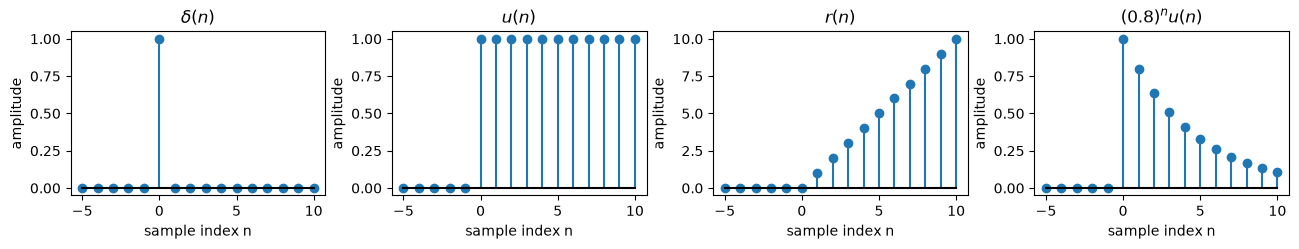

In [2]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)       # unit impulse
step  = (n >= 0).astype(float)       # unit step
ramp  = n * step                     # unit ramp
expo  = 0.8**n * step                # real exponential, causal

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        [r"$\delta(n)$", r"$u(n)$", r"$r(n)$", r"$(0.8)^n u(n)$"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("sample index n")
    ax.set_ylabel("amplitude")
plt.tight_layout()
plt.show()

### Check the code against values I can compute by hand

Before trusting the plot, verify a few samples analytically:
$\delta(0)=1$, $u(0)=1$, $r(1)=1$, $(0.8)^1 = 0.8$, $(0.8)^2 = 0.64$, $(0.8)^{10} = 0.1074$.

In [3]:
check = [
    ("n",            n[[0, 5, 6, 7, 15]].astype(float)),
    ("delta(n)",     delta[[0, 5, 6, 7, 15]]),
    ("u(n)",         step[[0, 5, 6, 7, 15]]),
    ("r(n)",         ramp[[0, 5, 6, 7, 15]]),
    ("(0.8)^n u(n)", expo[[0, 5, 6, 7, 15]]),
]
for k, v in check:
    vals = [0.0 if val == 0 else val for val in v]   # avoid printing -0.0000
    print(f"{k:>13}:", " ".join(f"{val:8.4f}" for val in vals))

assert delta[5] == 1 and step[0] == 0 and step[5] == 1
assert np.isclose(ramp[6], 1) and np.isclose(expo[6], 0.8) and np.isclose(expo[15], 0.8**10)
assert np.all(delta[[0, 1, 2, 3, 4, 6]] == 0)      # impulse is zero everywhere but n = 0
print("\nall analytic checks passed")

            n:  -5.0000   0.0000   1.0000   2.0000  10.0000
     delta(n):   0.0000   1.0000   0.0000   0.0000   0.0000
         u(n):   0.0000   1.0000   1.0000   1.0000   1.0000
         r(n):   0.0000   0.0000   1.0000   2.0000  10.0000
 (0.8)^n u(n):   0.0000   1.0000   0.8000   0.6400   0.1074

all analytic checks passed


## Task 1.2 — Change the parameters

### (a) $(a)^n u(n)$ for $a = 0.5$, $a = -0.8$ and $a = 1.1$

Each case gets its own y-axis: $1.1^{10} \approx 2.59$ while $0.5^{10} \approx 0.001$, so a shared
axis would flatten two of the three curves.

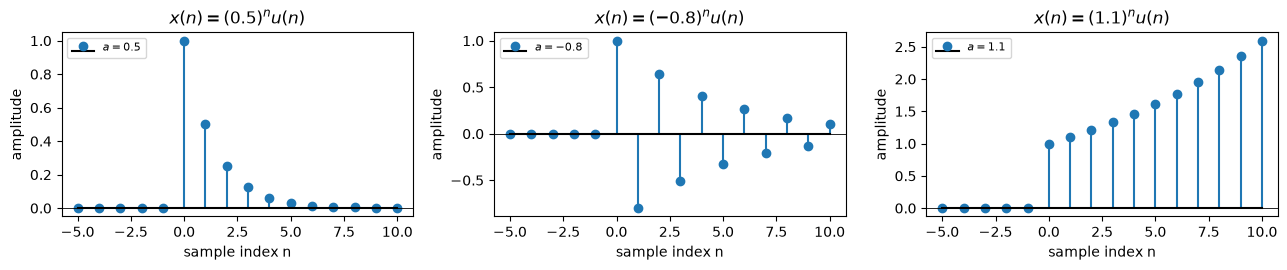

a =  0.5:  x(0)=1.000  x(1)=0.500  x(5)=0.031  x(10)=0.001
a = -0.8:  x(0)=1.000  x(1)=-0.800  x(5)=-0.328  x(10)=0.107
a =  1.1:  x(0)=1.000  x(1)=1.100  x(5)=1.611  x(10)=2.594


In [4]:
a_vals = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, a_vals):
    xa = a**n * step
    ax.stem(n, xa, basefmt="k-", label=f"$a={a}$")
    ax.set_title(f"$x(n)=({a})^n u(n)$")
    ax.set_xlabel("sample index n")
    ax.set_ylabel("amplitude")
    ax.axhline(0, color="k", lw=0.6)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

for a in a_vals:
    xa = a**n * step
    print(f"a = {a:>4}:  x(0)={xa[5]:.3f}  x(1)={xa[6]:.3f}  x(5)={xa[10]:.3f}  x(10)={xa[15]:.3f}")

- $a = 0.5$: monotonic decay — each sample is half the previous one.
- $a = -0.8$: alternating sign with decaying magnitude (the sign flips every sample).
- $a = 1.1$: unbounded growth, $|x(n)| \to \infty$. This is the case that matters for stability
  (see Analysis question 3).

### (b) $\cos(2\pi n/8)$ and $\cos(2\pi n/7.5)$ for $0 \le n \le 40$

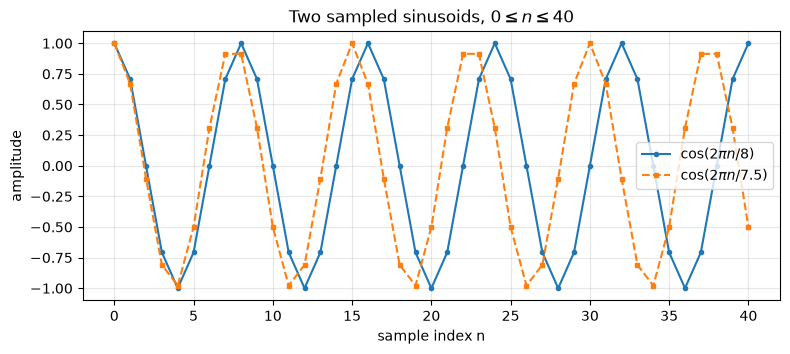

In [5]:
n2 = np.arange(0, 41)

x8  = np.cos(2*np.pi*n2/8)
x75 = np.cos(2*np.pi*n2/7.5)

plt.plot(n2, x8,  "o-", ms=3, label=r"$\cos(2\pi n/8)$")
plt.plot(n2, x75, "s--", ms=3, label=r"$\cos(2\pi n/7.5)$")
plt.title(r"Two sampled sinusoids, $0 \leq n \leq 40$")
plt.xlabel("sample index n")
plt.ylabel("amplitude")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Which one repeats exactly?

Measure it instead of eyeballing it. A sequence is periodic with period $N$ when
$x(n+N) = x(n)$ for every $n$.

In [6]:
def max_shift_error(x, N):
    # largest mismatch between x[n+N] and x[n] over the available overlap
    return np.max(np.abs(x[N:] - x[:-N]))

print("period-candidate errors (0 means an exact repeat):")
for name, x in [("cos(2*pi*n/8)", x8), ("cos(2*pi*n/7.5)", x75)]:
    print(f"\n{name}")
    for N in [7, 8, 15, 16]:
        if N < len(x):
            print(f"   shift N={N:>2}: max|x(n+N)-x(n)| = {max_shift_error(x, N):.2e}")

period-candidate errors (0 means an exact repeat):

cos(2*pi*n/8)
   shift N= 7: max|x(n+N)-x(n)| = 7.07e-01
   shift N= 8: max|x(n+N)-x(n)| = 2.02e-15
   shift N=15: max|x(n+N)-x(n)| = 7.07e-01
   shift N=16: max|x(n+N)-x(n)| = 2.27e-15

cos(2*pi*n/7.5)
   shift N= 7: max|x(n+N)-x(n)| = 4.14e-01
   shift N= 8: max|x(n+N)-x(n)| = 4.14e-01
   shift N=15: max|x(n+N)-x(n)| = 3.50e-15
   shift N=16: max|x(n+N)-x(n)| = 8.09e-01


**Answer.** Both of them repeat exactly — but with **different periods**, and only the first one
*looks* periodic in this window.

- $\cos(2\pi n/8)$: period $N = 8$ samples (error $\approx 10^{-16}$ at shift 8). Five whole cycles
  fit in $0 \le n \le 40$, so the curve visibly repeats.
- $\cos(2\pi n/7.5)$: period $N = 15$ samples (error $\approx 10^{-16}$ at shift 15, large at shift 7
  or 8). Because $\frac{2\pi}{7.5} = 2\pi\cdot\frac{2}{15}$, the normalised frequency is the rational
  number $2/15$, and $N = 15$ is the smallest integer with $N\cdot\frac{2}{15}$ an integer. The period
  is simply not a whole number of samples ($7.5$), so it never lines up at the edges of a 41-sample
  plot.

This is the general rule to be formalised in Week 3: $x(n)=\cos(\omega_0 n)$ is periodic **iff**
$\omega_0/2\pi$ is rational, and the period is the denominator of that fraction in lowest terms.

## Task 1.3 — Working with audio

**In Google Colab:** record 3–5 s of your voice on your phone, get the WAV onto your computer, then
drag it into the Colab **Files** panel (left sidebar → upload). It lands at `/content/my_voice.wav`.
The cell below also looks in `data/my_voice.wav`, so it works both here and in a local clone of the
repository:

```
COU07506-labs/
    COU07506_Week01_<RegNo>.ipynb
    data/my_voice.wav
```

If neither path exists the cell falls back to a synthetic 16 kHz test signal and says so — that is a
placeholder, **not** your recording, so do not present that printout as your answer to Analysis
question 1.

`wavfile.read` returns `int16` for a normal WAV, so `x` is cast to `float64` *before* the peak is
computed. The trap is `np.abs` on an integer array: `abs(-32768)` wraps to $-32768$, because that
value has no positive `int16` counterpart. The peak is then under-reported, and if that sample is
the largest in magnitude the reported peak is *negative*. (`x / peak` is itself safe — true
division promotes to `float64` — the error would be in the peak, not the division.)


source      : my recording, data\my_voice.wav
fs          : 48000 Hz (48.0 kHz)
duration    : 5.57 s
samples     : 267528
one minute  : 2880000 samples (5.76 MB at 16 bit mono)


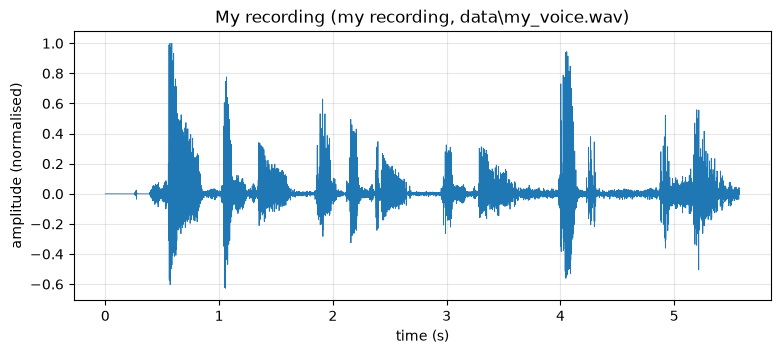

In [7]:
import os
from IPython.display import Audio

# In Colab a Files-panel upload lands at /content/my_voice.wav, whereas the
# repository keeps it in data/. Try both before falling back to the test signal.
candidates = [os.path.join("data", "my_voice.wav"), "my_voice.wav"]
fname = next((f for f in candidates if os.path.exists(f)), None)

if fname is not None:
    fs, x = wavfile.read(fname)
    x = x.astype(np.float64)                 # int16 -> float BEFORE np.abs() so the peak is right
    if x.ndim > 1:                           # stereo -> mono
        x = x.mean(axis=1)
    peak = np.max(np.abs(x))
    if peak > 0:
        x = x / peak                         # normalise to [-1, 1]
    source = f"my recording, {fname}"
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
    source = "FALLBACK test signal (no my_voice.wav found)"

t = np.arange(len(x)) / fs
duration = len(x) / fs
print(f"source      : {source}")
print(f"fs          : {fs} Hz ({fs/1000:.1f} kHz)")
print(f"duration    : {duration:.2f} s")
print(f"samples     : {len(x)}")
print(f"one minute  : {60*int(fs)} samples ({60*int(fs)*2/1e6:.2f} MB at 16 bit mono)")

plt.plot(t, x, lw=0.6)
plt.title(f"My recording ({source})")
plt.xlabel("time (s)")
plt.ylabel("amplitude (normalised)")
plt.grid(alpha=0.3)
plt.show()

Audio(x, rate=int(fs))

If the printed `source` says FALLBACK, add your WAV and re-run this cell before the checkpoint.

## Task 1.4 — The same in Octave (optional)

Not attempted in the submitted notebook (GNU Octave is not installed on this machine). The equivalent
Octave code is shown for reference; the differences from Python are:

| Python | Octave |
|---|---|
| `n = np.arange(-5, 11)` | `n = -5:10;` |
| `(n == 0).astype(float)` | `double(n == 0)` |
| `n * step` | `n .* step` (element-wise by default in Octave, but `.` is required for clarity/power) |
| `0.8**n` | `0.8 .^ n` |
| `plt.subplot(1, 4, k)` | `subplot(1, 4, k)` |
| `stem(n, x, basefmt="k-")` | `stem(n, x)` |

```octave
n = -5:10;
delta = double(n == 0);
step  = double(n >= 0);
ramp  = n .* step;
expo  = 0.8 .^ n .* step;

figure;
subplot(1,4,1); stem(n, delta); title('delta(n)'); xlabel('n');
subplot(1,4,2); stem(n, step ); title('u(n)');     xlabel('n');
subplot(1,4,3); stem(n, ramp ); title('r(n)');     xlabel('n');
subplot(1,4,4); stem(n, expo ); title('(0.8)^n u(n)'); xlabel('n');
```

## Analysis questions

### 1. What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?

The rate is printed by the Task 1.3 cell, for my own file `data/my_voice.wav`:

| Quantity | Value |
|---|---|
| File | `data/my_voice.wav` (mono, 16-bit PCM) |
| Sampling rate $f_s$ | **48 000 Hz (48 kHz)** |
| Duration | 5.57 s (267 528 samples) |

One minute of it in mono is $60f_s = 60 	imes 48\,000 = \mathbf{2\,880\,000}$ numbers. At 16 bits
each that is $2\,880\,000 	imes 2 = 5\,760\,000$ bytes $\approx \mathbf{5.76\ MB}$ (5.49 MiB).
A 44.1 kHz phone would need 2 646 000 samples instead ($\approx$ 5.29 MB); the sample count is simply
$60f_s$ whatever the rate.

48 kHz is the rate phones use for music playback, not a requirement of speech. A voice signal carries
almost nothing above about 4 kHz, so by the sampling theorem (Week 2, §1.2) 8 kHz would already be
enough — which is why telephony uses 8 kHz. Recording at 48 kHz keeps the file compatible with audio
hardware and lets the Week 2 aliasing experiment start from a signal with plenty of bandwidth.

### 2. Why is a stem plot more appropriate than a continuous line for $x(n)$?

$x(n)$ is defined **only** at integer $n$. A continuous line traces a curve through every
intermediate value, which asserts sample values that were never measured or computed — it implies
interpolation that did not happen. A stem plot marks each sample with a dot and drops a vertical line
to the axis, so the reader sees both the sample value and the fact that the signal is undefined
between samples. It also makes the amplitude at $n=0$ unambiguous, which matters for $\delta(n)$ and
$u(n)$.

### 3. For $a = 1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response (§1.7)?

**BIBO stability.** A system is bounded-input bounded-output stable iff its impulse response is
absolutely summable, $\sum_{n}|h(n)| < \infty$. For $h(n) = (1.1)^n u(n)$ the sum is a geometric
series with ratio $1.1 > 1$, so it diverges: a *bounded* input (even a single unit sample) produces
an unbounded output. Equivalently, the pole at $z = 1.1$ lies outside the unit circle. The boundary
case $|a| = 1$ is also not stable (the sum does not converge).

## Task 1.5 — Repository and submission

- Git repository: `COU07506-labs` — **TODO: paste the repository link here** (GitHub / GitLab / local).
- Suggested layout, which is what the paths in Task 1.3 assume:

```
COU07506-labs/
    COU07506_Week01_<RegNo>.ipynb
    data/my_voice.wav
    README.md
```

- Commit commands, run once from `COU07506-labs/`:

```
git init
git add COU07506_Week01_<RegNo>.ipynb README.md
git commit -m "Week 1 Lab 0: elementary sequences and first audio"
git remote add origin <your-repo-url>
git push -u origin main
```

- `data/my_voice.wav` **is committed**, so the notebook is reproducible for the demonstrator. The cell
  still falls back to a synthetic 16 kHz signal (and prints that it did) if the file is absent, so a
  fresh clone that drops the WAV still runs.


**Submission checklist**

- [ ] Title cell filled in (name, reg no, date, group)
- [ ] Tasks 1.1, 1.2, 1.3 present with plots
- [ ] Pre-lab and analysis questions answered
- [ ] Every plot has a title, labelled axes and a legend where more than one curve is shown
- [ ] Kernel restarted and all cells run top-to-bottom without errors
- [ ] Repository link pasted above and notebook uploaded to DIT-eLMS
- [ ] Mini-project group formed (3–5 students) and two topics posted on the eLMS forum

## AI-use statement

**Tool used:** Buffy (Codebuff AI coding agent), used as a chat/code assistant in the browser.

**Tasks where it was used:** drafting the plotting code for Tasks 1.1, 1.2 and 1.3 (including the
stereo-to-mono handling), and suggesting the wording of the analysis answers, which I rewrote in my
own words.

**How the results were checked:**

1. The standard imports and every line were explained to me until I could reproduce them unaided.
2. Task 1.1 was verified against hand-computed values at $n = 0, 1, 2, 10$:
   $\delta(0)=1$, $u(0)=1$, $r(1)=1$, $0.8^1 = 0.8$, $0.8^2 = 0.64$, $0.8^{10} = 0.1074$ — the
   `assert` cell passes.
3. The periodicity claim in Task 1.2(b) was verified numerically by the shift-error cell
   ($\sim 10^{-16}$ at $N = 8$ and $N = 15$ respectively), not accepted as stated.
4. The audio cell's sample count and duration were checked by hand: `samples / fs` must equal the
   printed duration.
5. I restarted the kernel and re-ran all cells myself; the notebook runs top to bottom without
   errors.